In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image

Normalizing intensities to a standard range makes images more comparable under varying lighting. Explore functions like cv2.normalize or scaling by 255.0 to implement this consistently.

 Clipping high intensities limits the influence of extremely bright pixels on subsequent analysis while keeping the rest of the data unchanged.

### Reading and Showing Images

In [2]:
og_img = cv2.imread('data/Img1.jpg', cv2.IMREAD_UNCHANGED)

if og_img is not None:
    # cv2.imshow('Unchanged', og_img)
    # cv2.waitKey(0)
    # cv2.destroyAllWindows()
    # cv2.waitKey(1)

    print(og_img.shape)

(3000, 4000, 3)


Flags

cv2.IMREAD_GRAYSCALE or 0: Loads image in grayscale mode,   
cv2.IMREAD_COLOR or 1: Loads a color image. Any transparency of image will be neglected. It is the default flag.     
cv2.IMREAD_UNCHANGED or -1: Loads image as such including alpha channel.

without extra cv2.waitKey(1) the kernel was dying as in Mac destroyAllWindows() only marks the window for closing, and the actual teardown happens inside waitKey. Without it, the window was left half-closed, and that state is what was killing the kernel.

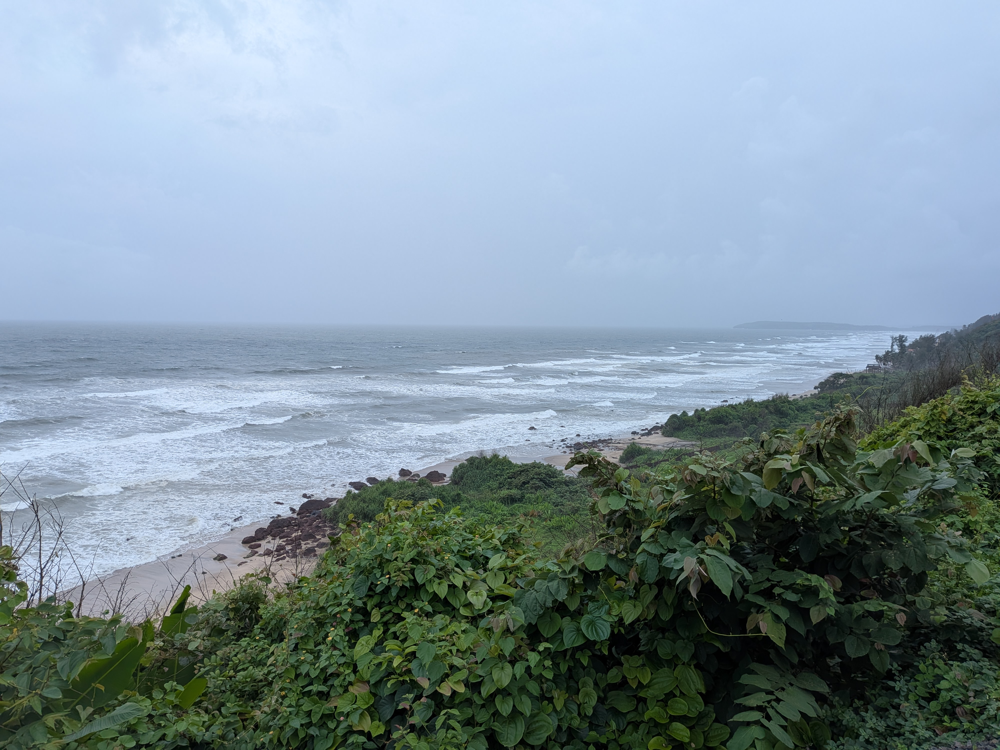

In [3]:
Image('data/Img1.jpg', width=400, height=300)

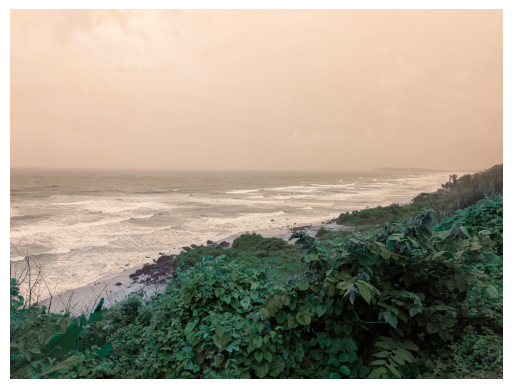

In [4]:
plt.imshow(og_img)
plt.axis("off")
plt.show()

OpenCV stores color images as 3D arrays with channels in BGR order by default.

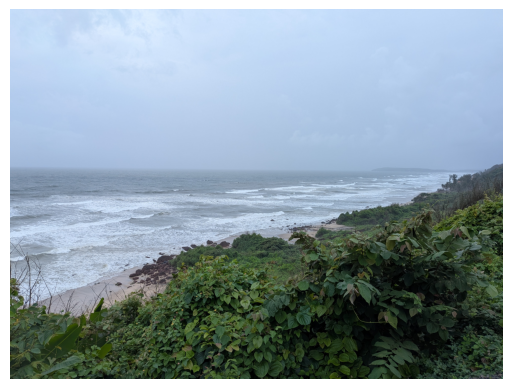

In [5]:
plt.imshow(cv2.cvtColor(og_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

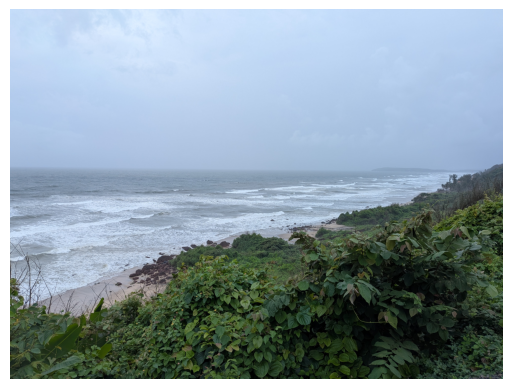

In [6]:
# For a 3-channel image, [:, :, ::-1] means: keep all rows, keep all columns, and read the channel axis backwards.
plt.imshow(og_img[:, :, ::-1])
plt.axis("off")
plt.show()

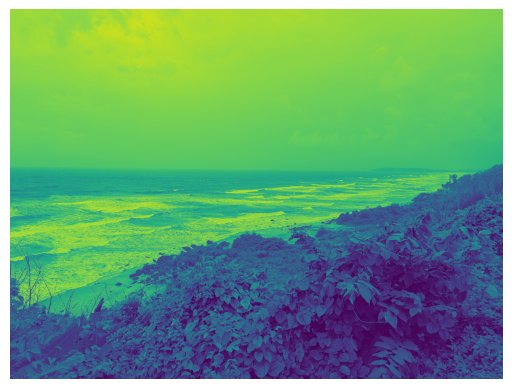

In [7]:
gray_img = cv2.imread('data/Img1.jpg', cv2.IMREAD_GRAYSCALE)

plt.imshow(gray_img)
plt.axis("off")
plt.show()

The image was loaded correctly. The colors come from how you display it. If you’re using plt.imshow(gray_img), matplotlib applies its default colormap (viridis) to single-channel images, which gives those green/yellow tones.

Even though the image was read in as a gray scale image, it won't necessarily display in gray scale when using imshow(). matplotlib uses different color maps and it's possible that the gray scale color map is not set

What cvtColor does here is replicate the gray values into three channels, and matplotlib then renders them as plain gray instead of applying the colormap.

In [8]:
print(gray_img.shape, gray_img.dtype)

(3000, 4000) uint8


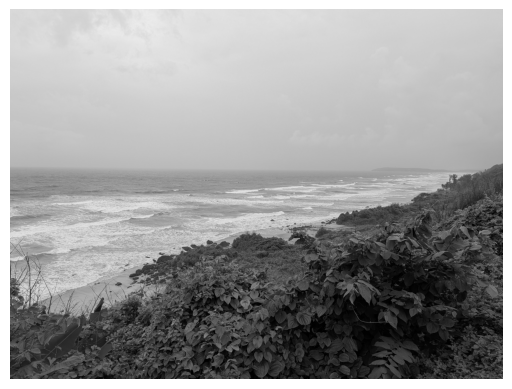

In [9]:
plt.imshow(gray_img, cmap='gray')
plt.axis("off")
plt.show()

In [10]:
cv2.imwrite('data/gray_img1.jpg', gray_img)

True

### Editing Image Size

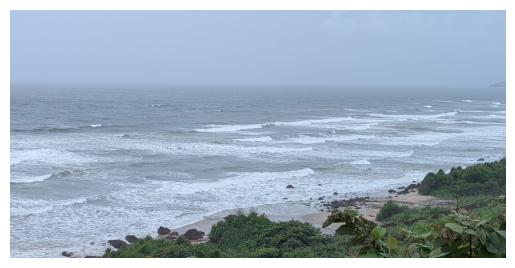

In [11]:
x, y, width, height = 1000, 1000, 2000, 1000

cropped_img = og_img[y:y+height, x:x+width]
plt.imshow(cv2.cvtColor(cropped_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

here its height, width

In [12]:
copied_img = og_img.copy()
# does not chane with any changes made to og_img

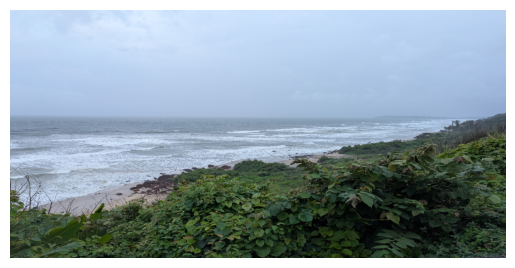

In [13]:
resized_img = cv2.resize(og_img, (2000,1000))
plt.imshow(cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

here its width, height

In [14]:
# Specifying Scaling Factor using fx and fy
print(og_img.shape)

print(cv2.resize(og_img, None, fx=2, fy=2).shape)

print(cv2.resize(og_img, None, fx=0.2, fy=0.2).shape)

(3000, 4000, 3)
(6000, 8000, 3)
(600, 800, 3)


In [15]:
# Resize while maintaining aspect ratio
desired_width = 100
aspect_ratio = desired_width / og_img.shape[1]
desired_height = int(og_img.shape[0] * aspect_ratio)
dim = (desired_width, desired_height)

# Resize image
resized_region = cv2.resize(og_img, dsize=dim, interpolation=cv2.INTER_AREA)
# plt.imshow(resized_cropped_region)
print(resized_region.shape, og_img.shape, aspect_ratio)

(75, 100, 3) (3000, 4000, 3) 0.025


### Image Color Channels and their Manipulation

Text(0.5, 1.0, 'merged')

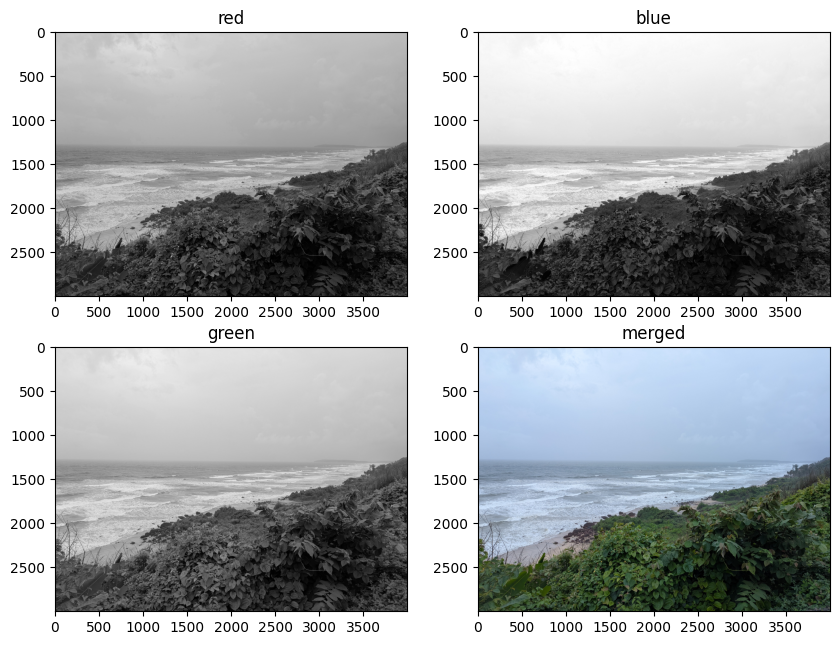

In [16]:
b,g, r = cv2.split(og_img)

plt.figure(figsize=[10,15])
plt.subplot(221)
plt.imshow(r, cmap='gray')
plt.title("red")

plt.subplot(222)
plt.imshow(b, cmap='gray')
plt.title("blue")

plt.subplot(121)
plt.imshow(g, cmap='gray')
plt.title("green")

merged_img = cv2.merge((b,g,r))
plt.subplot(122)
plt.imshow(merged_img[:, :, ::-1])
plt.title("merged")

Text(0.5, 1.0, 'img hsv')

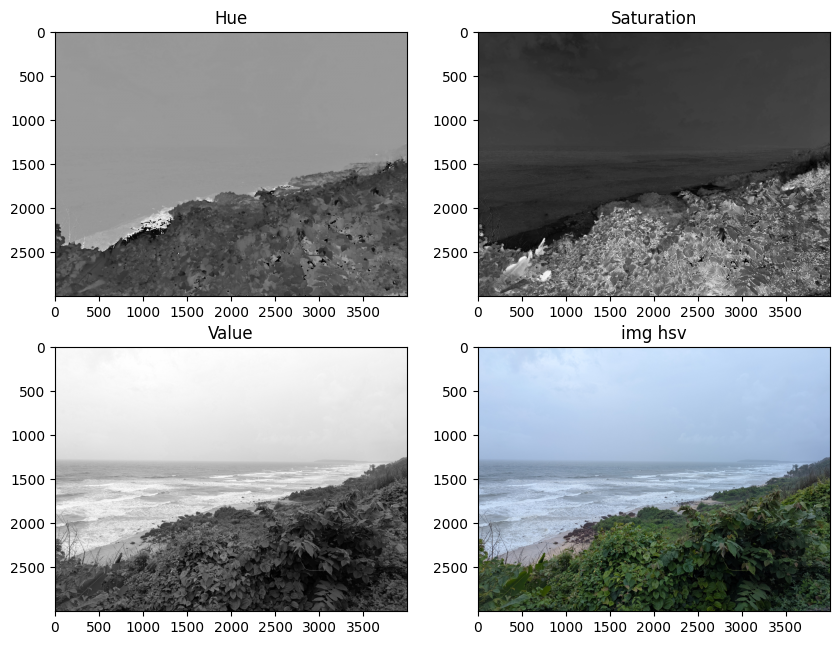

In [17]:
# h, s ,v = hue, saturation and value

img_hsv = cv2.cvtColor(og_img, cv2.COLOR_BGR2HSV)
h,s,v = cv2.split(img_hsv)


plt.figure(figsize=[10,15])
plt.subplot(221)
plt.imshow(h, cmap='gray')
plt.title("Hue")

plt.subplot(222)
plt.imshow(s, cmap='gray')
plt.title("Saturation")

plt.subplot(121)
plt.imshow(v, cmap='gray')
plt.title("Value")

# merged_img = cv2.merge((b,g,r))
plt.subplot(122)
plt.imshow(og_img[:, :, ::-1])
plt.title("img hsv")

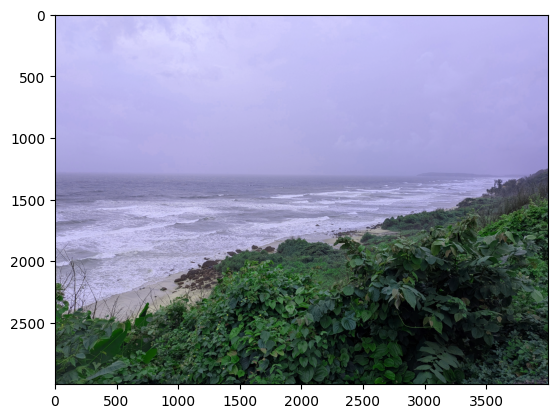

In [18]:
# Adding more hue

h_new = h + 15
hsv_merged = cv2.merge((h_new,s,v))
rbg_fromhsv = cv2.cvtColor(hsv_merged, cv2.COLOR_HSV2RGB)

plt.imshow(rbg_fromhsv)

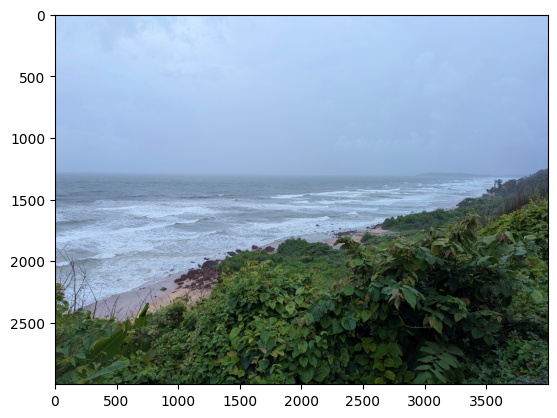

In [19]:
s_new = s + 15
hsv_merged2 = cv2.merge((h,s_new,v))
rbg_fromhsv2 = cv2.cvtColor(hsv_merged2, cv2.COLOR_HSV2RGB)

plt.imshow(rbg_fromhsv2)

HSV is useful for color based image segmentation and filtering as it separates color information from intensity.

Grayscale represents intensity only, this is useful for tasks like edge detection.

### Editing Small parts of an Image

In [20]:
print(og_img.shape)

(3000, 4000, 3)


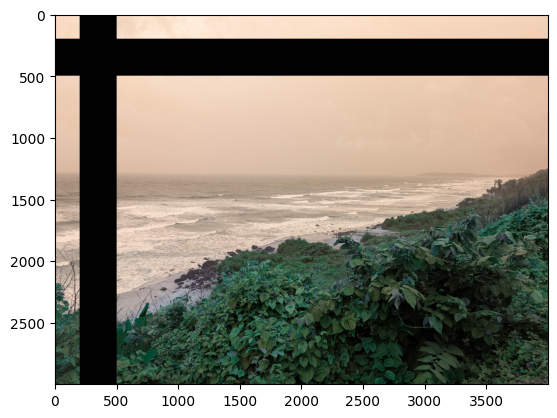

In [21]:
manipulated_img = og_img.copy()

manipulated_img[200:500, :, :] = 1
manipulated_img[:, 200:500, :] = 1
plt.imshow(manipulated_img)

Text(0.5, 1.0, 'Original')

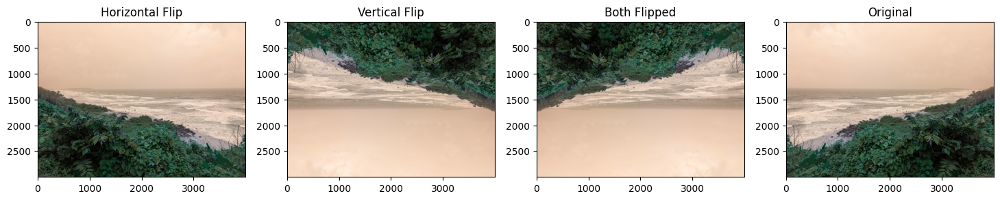

In [22]:
og_img_flipped_horz = cv2.flip(og_img, 1)
og_img_flipped_vert = cv2.flip(og_img, 0)
og_img_flipped_both = cv2.flip(og_img, -1)

# Show the images
plt.figure(figsize=(18, 5))
plt.subplot(141)
plt.imshow(og_img_flipped_horz)
plt.title("Horizontal Flip")

plt.subplot(142)
plt.imshow(og_img_flipped_vert)
plt.title("Vertical Flip")

plt.subplot(143)
plt.imshow(og_img_flipped_both)
plt.title("Both Flipped")

plt.subplot(144)
plt.imshow(og_img)
plt.title("Original")

### Image Annotations

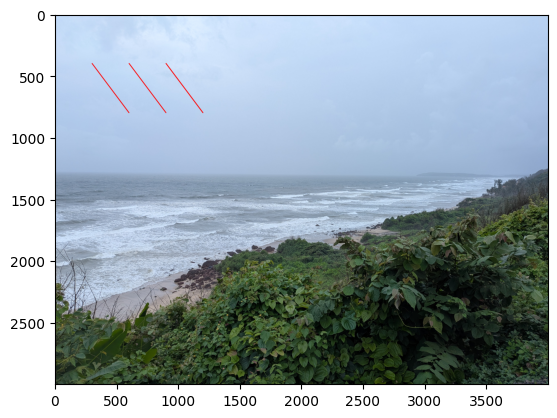

In [23]:
base_image = og_img.copy()

cv2.line(img=base_image, pt1=(300,400), pt2=(600,800), color=(0,0,255), thickness=5, lineType=cv2.LINE_4)
cv2.line(img=base_image, pt1=(600,400), pt2=(900,800), color=(0,0,255), thickness=5, lineType=cv2.LINE_8)
cv2.line(img=base_image, pt1=(900,400), pt2=(1200,800), color=(0,0,255), thickness=5, lineType=cv2.LINE_AA)

plt.imshow(base_image[:,:, ::-1])

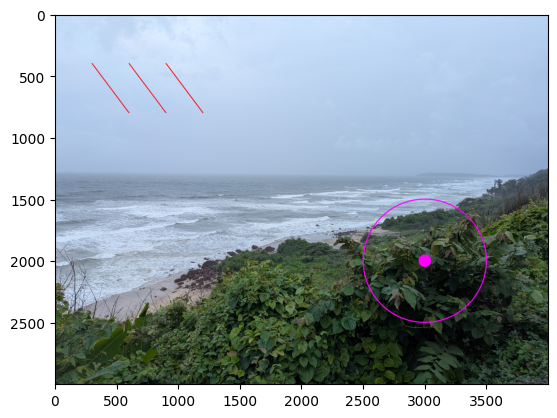

In [24]:
cv2.circle(img=base_image, center=(3000,2000), radius=500, color=(255,0,255), thickness=7, lineType=cv2.LINE_AA)
cv2.circle(img=base_image, center=(3000,2000), radius=50, color=(255,0,255), thickness=-2, lineType=cv2.LINE_AA)

plt.imshow(base_image[:,:, ::-1])

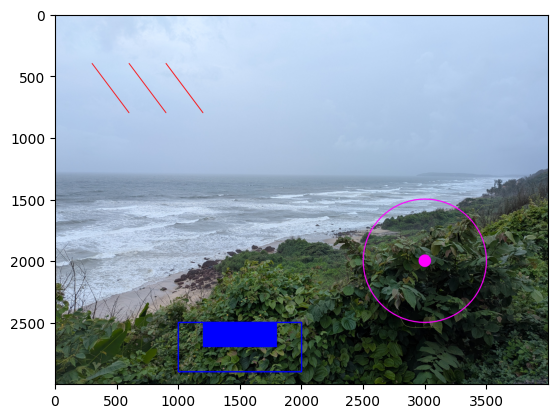

In [25]:
# rectangle p1: top left, p2: bottom right

cv2.rectangle(img=base_image, pt1=(1000,2500), pt2=(2000, 2900), color=(255,0,0), thickness=9, lineType=cv2.LINE_AA)

cv2.rectangle(img=base_image, pt1=(1200,2500), pt2=(1800, 2700), color=(255,0,0), thickness=-9, lineType=cv2.LINE_AA)


plt.imshow(base_image[:,:,::-1])

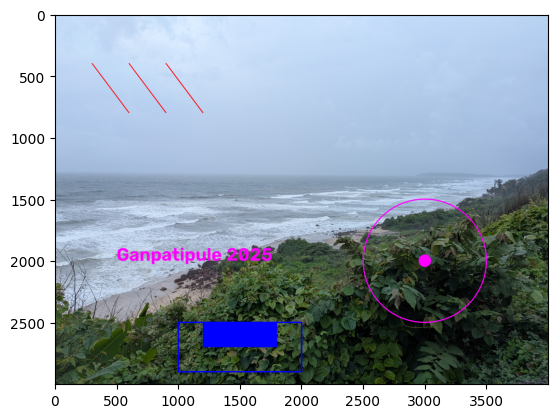

In [26]:
text = 'Ganpatipule 2025'

cv2.putText(img=base_image, text=text, org=(500, 2000), fontFace=cv2.FONT_HERSHEY_DUPLEX, fontScale=5, color=(255,0,255))
cv2.putText(img=base_image, text=text, org=(200, 1000), fontFace=cv2.FONT_HERSHEY_DUPLEX, fontScale=-10, color=(255,0,255))

plt.imshow(base_image[:,:,::-1])


### Image Enhancements

Text(0.5, 1.0, 'Brighter Image')

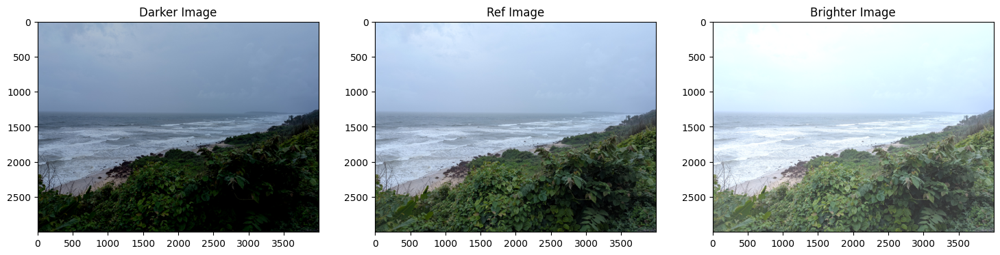

In [27]:
og_img_rbg = cv2.cvtColor(og_img, cv2.COLOR_BGR2RGB)

## Adjusting Brigtness (Addition or substraction)
brig_mat = np.ones(og_img_rbg.shape, dtype="uint8")*50
og_img_rbg_darker = cv2.subtract(og_img_rbg, brig_mat)

og_img_rbg_brigther = cv2.add(og_img_rbg, brig_mat)

plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(og_img_rbg_darker); plt.title("Darker Image")
plt.subplot(132); plt.imshow(og_img_rbg); plt.title("Ref Image")
plt.subplot(133); plt.imshow(og_img_rbg_brigther); plt.title("Brighter Image")

Text(0.5, 1.0, 'High Contrast Image')

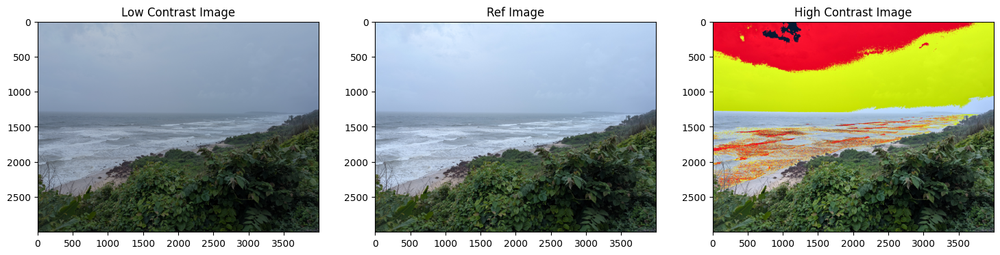

In [28]:
## Adjusting Contrast (Multipy or Divide)
hig_mat = np.ones(og_img_rbg.shape, dtype="uint8")*1.2
low_mat = np.ones(og_img_rbg.shape, dtype="uint8")*0.8

og_img_rbg_high = np.uint8(cv2.multiply(np.float64(og_img_rbg), hig_mat))
og_img_rbg_low = np.uint8(cv2.multiply(np.float64(og_img_rbg), low_mat))

plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(og_img_rbg_low); plt.title("Low Contrast Image")
plt.subplot(132); plt.imshow(og_img_rbg); plt.title("Ref Image")
plt.subplot(133); plt.imshow(og_img_rbg_high); plt.title("High Contrast Image")

Can you see the weird colors in some areas of the image after multiplication?

The issue is that after multiplying, the values which are already high, are becoming greater than 255. Thus, the overflow issue. It rollsover and the value becomes closer to 0.

Text(0.5, 1.0, 'High Contrast Image')

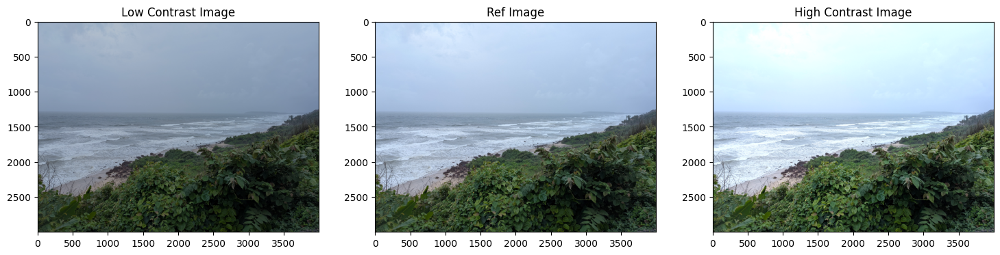

In [29]:
# Handling Overflow using np.clip
og_img_rbg_high_2 = np.uint8(np.clip((cv2.multiply(np.float64(og_img_rbg), hig_mat)),0, 255))

plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(og_img_rbg_low); plt.title("Low Contrast Image")
plt.subplot(132); plt.imshow(og_img_rbg); plt.title("Ref Image")
plt.subplot(133); plt.imshow(og_img_rbg_high_2); plt.title("High Contrast Image")

##### Image Thresholding
Binary Images have a lot of use cases in Image Processing. One of the most common use cases is that of creating masks. Image Masks allow us to process on specific parts of an image keeping the other parts intact. Image Thresholding is used to create Binary Images from grayscale images. You can use different thresholds to create different binary images from the same original image.

Text(0.5, 1.0, 'OTSU Mask')

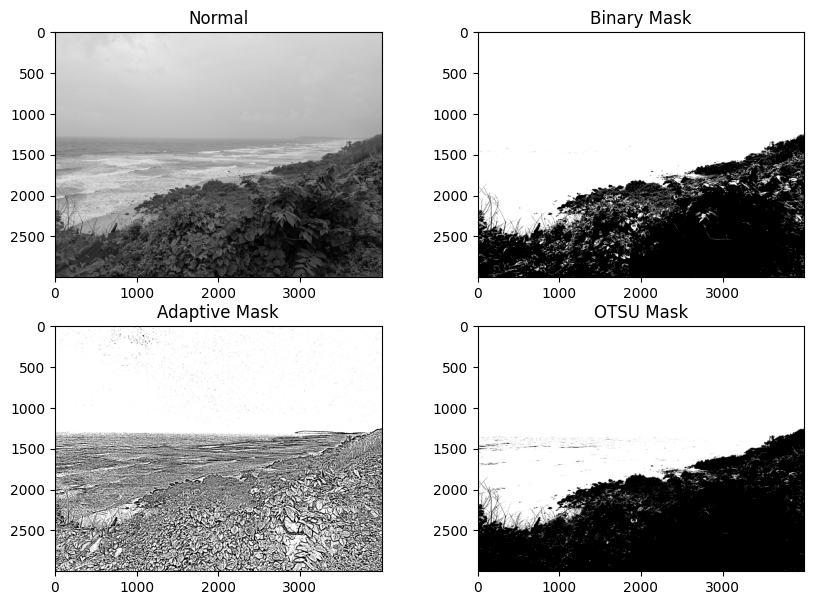

In [64]:
retval, img_thresh = cv2.threshold(gray_img, 100, 255, cv2.THRESH_BINARY)
img_thresh2 = cv2.adaptiveThreshold(gray_img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 3)
retval, img_thresh3 = cv2.threshold(gray_img, 100, 255, cv2.THRESH_OTSU)

plt.figure(figsize=[10,7])
plt.subplot(221); plt.imshow(gray_img, cmap='gray'); plt.title("Normal")
plt.subplot(222); plt.imshow(img_thresh, cmap='gray'); plt.title("Binary Mask")
plt.subplot(223); plt.imshow(img_thresh2, cmap='gray'); plt.title("Adaptive Mask")
plt.subplot(224); plt.imshow(img_thresh3, cmap='gray'); plt.title("OTSU Mask")

Object Segmentation, Noise reduction, Feature Extraction, Defect Detection, Edge Detection, Image Enhancements, Pattern Recognition, Quality Assurance, Material Analysis, Motion Detection, Biomedical Imaging

Text(0.5, 1.0, 'NOT')

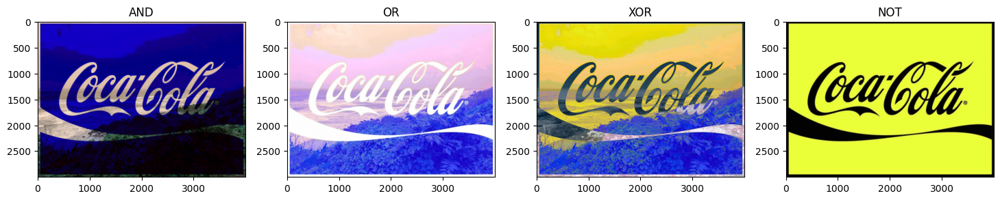

In [ ]:
coke_img = cv2.imread('data/coke-logo.jpg', cv2.IMREAD_UNCHANGED)
coke_img = cv2.resize(coke_img, (4000,3000))
result = cv2.bitwise_and(og_img, coke_img, mask=None)
result2 = cv2.bitwise_or(og_img, coke_img, mask=None)
result3 = cv2.bitwise_xor(og_img, coke_img, mask=None)
result4 = cv2.bitwise_not(coke_img, mask=None)

plt.figure(figsize=[18,5])
plt.subplot(141); plt.imshow(result); plt.title("AND")
plt.subplot(142); plt.imshow(result2); plt.title("OR")
plt.subplot(143); plt.imshow(result3); plt.title("XOR")
plt.subplot(144); plt.imshow(result4); plt.title("NOT")

# og_img.shape,  coke_img.shape

## left_shift_img = coke_img << 1
## right_shift_img = coke_img >> 1


| Function | Rule (per bit) | Use for |
|---|---|---|
| `cv2.bitwise_and(a, b, mask=)` | 1 only if both are 1 | **Extract a region:** keep pixels under the mask |
| `cv2.bitwise_or(a, b)` | 1 if either is 1 | Combine masks or images (union) |
| `cv2.bitwise_xor(a, b)` | 1 if they differ | Find differences between two binary images |
| `cv2.bitwise_not(a)` | flip every bit (255 − x for uint8) | Invert a mask or image |

Text(0.5, 1.0, 'NOT')

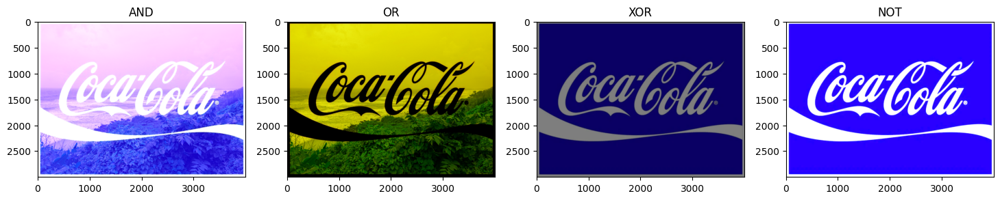

In [59]:
result = cv2.add(og_img, coke_img, mask=None)
result2 = cv2.subtract(og_img, coke_img, mask=None)
result3 = cv2.divide(coke_img, 2)
result4 = cv2.multiply(coke_img, 2)

plt.figure(figsize=[18,5])
plt.subplot(141); plt.imshow(result); plt.title("AND")
plt.subplot(142); plt.imshow(result2); plt.title("OR")
plt.subplot(143); plt.imshow(result3); plt.title("XOR")
plt.subplot(144); plt.imshow(result4); plt.title("NOT")

| Function | Computes | Use for |
|---|---|---|
| `cv2.add(a, b)` | a + b, clipped at 255 | Brightening, combining intensities |
| `cv2.subtract(a, b)` | a − b, clipped at 0 | Darkening, removing a background |
| `cv2.multiply(a, b, scale=1)` | a × b × scale | Contrast adjustment, applying a weight map |
| `cv2.divide(a, b, scale=1)` | a / b × scale | Flat-field and illumination correction |

In [32]:
arr1 = np.array([200, 250], dtype=np.uint8).reshape(-1, 1)
arr2 = np.array([40, 40], dtype=np.uint8).reshape(-1, 1)
add_numpy = arr1+arr2
add_cv2 = cv2.add(arr1, arr2)

add_numpy, add_cv2

(array([[240],
        [ 34]], dtype=uint8),
 array([[240],
        [255]], dtype=uint8))

NumPy + does modulo arithmetic on uint8. 250 + 40 = 290, and 290 mod 256 = 34. It overflows silently, with no error or warning.  
cv2.add clips (saturates) to the dtype’s range, so anything above 255 becomes 255. Subtraction clips at 0 in the same way, so cv2.subtract never goes negative.

### Histograms

Grayscale Histograms represent the distribution ​of pixel intensities in grayscale images. ​They show the frequency of intensity values ranging ​from 0, black, to 255, white, in the image. 

​Color Histograms ​For color images, histograms can be computed separately for ​each color channel, red, green, blue in RGB color space ​or for different color spaces like hsv, hue, saturation, value. ​Color histograms reveal the distribution of ​color tones and intensities in the image. 

​Normalized Histograms scale the frequency values to a range ​of 0 to 1, making them useful for comparing ​histograms of images with different sizes or intensity ranges. ​

Cumulative Histograms show the cumulative distribution of pixel intensities. ​They are useful for analyzing the cumulative ​effects of contrast adjustments or histogram equalization techniques. 

Equalized Histograms equalization is a technique that redistributes the intensity ​values in an image to improve contrast and enhance details. ​Equalized histograms reflect this redistribution of pixel intensities. ​

Sparse Histograms ​Sparse histograms are histograms with fewer bins focusing on ​specific intensity ranges or features of interest in the image. ​They are used in applications where detailed intensity ​information is not required for the entire image. 

​Joint Histograms are used in image registration and alignment tasks. ​They represent the joint distribution of pixel intensities from two different ​images, often used in comparing images for similarity or alignment purposes. 

​Smooth Histograms ​Smooth histograms apply smoothing techniques such as Gaussian ​smoothing or kernel density estimation to reduce noise ​and provide a smoother representation of intensity distributions. 

Text(0.5, 1.0, 'R')

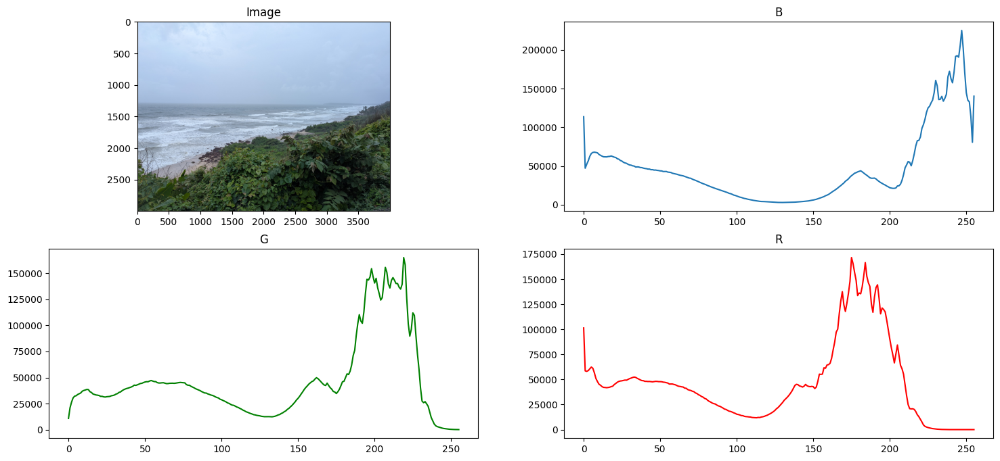

In [54]:
histogram_b = cv2.calcHist([og_img], [0], mask = None, histSize=[256], ranges=[0,256])
histogram_g = cv2.calcHist([og_img], [1], mask = None, histSize=[256], ranges=[0,256])
histogram_r = cv2.calcHist([og_img], [2], mask = None, histSize=[256], ranges=[0,256])

plt.figure(figsize=[18,8])

plt.subplot(221); plt.imshow(og_img_rbg); plt.title("Image")
plt.subplot(222); plt.plot(histogram_b); plt.title('B')
plt.subplot(223); plt.plot(histogram_g, color='g'); plt.title('G')
plt.subplot(224); plt.plot(histogram_r, color='r'); plt.title('R')

##### `cv2.calcHist`: why the image must be in a list

cv2.calcHist([img], [channel], mask, [bins], [range])

- The first argument must be a **list of images**, even when there is only one.
- **With `[img]`:** OpenCV gets one image (H, W, 3). `[0]` selects its blue channel, and every pixel is counted. The histogram sums to H × W.
- **Without the list (`img`):** OpenCV iterates the 3D array along axis 0 and treats it as H separate images of shape (W, 3). Channel `[0]` then refers to the first of those, so only the **top row** is counted.
- `[channel]` is 0, 1 or 2 for BGR, or 0 for a grayscale image.
- `ranges` is `[0, 256]`, since the upper bound is exclusive.

In [33]:
## Access computer camera
# import sys

# s = 0
# # if len(sys.argv) > 1:
# #     s = sys.argv[1]

# source = cv2.VideoCapture(s)

# win_name = 'Camera Preview'
# cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)

# while cv2.waitKey(1) != 27: # Escape
#     has_frame, frame = source.read()
#     if not has_frame:
#         break
#     cv2.imshow(win_name, frame)

# source.release()
# cv2.destroyWindow(win_name)

# Mac Kernel Crashes while using this code

In [34]:
## MAC Safe Access computer camera

cap = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)   # macOS backend
if not cap.isOpened():
    raise IOError("Cannot open camera")

while True:
    ret, frame = cap.read()
    if not ret:
        break
    cv2.imshow("camera", frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):   # click the window, press q
        break

cap.release()
cv2.destroyAllWindows()
cv2.waitKey(1)   # needed on macOS so the window actually closes

-1